In [1]:
import numpy as np
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [2]:
# Define directories, parameters
homepath = "/pscratch/sd/x/xueke/Github/"
t2m    = "t2m"
z      = "z"
swvl1  = "swvl1"
u      = "u"
v      = "v"
r      = "r"

# Define plot settings
crs = ccrs.PlateCarree(central_longitude=0)
step = 6
plt_min = -3            
plt_max = 3            
num = 21
levels = np.linspace(plt_min, plt_max, num)
ticks = np.arange(plt_min, plt_max+1, 1)
bounds = [str(y) for y in ticks]
pad = 0.03
labelsize = 20

In [3]:
# Define boundaries
lon_bnds = [-126, -100]      # Lager region  
lat_bnds = [28, 55]          # Lager region
lon_bnds_reg = [-125, -105]  # SWNA
lat_bnds_reg = [30, 45]      # SWNA
width = lon_bnds_reg[1] - lon_bnds_reg[0]
height = lat_bnds_reg[1] - lat_bnds_reg[0]

usa_shp_path = homepath +"data/cb_2018_us_state_500k/cb_2018_us_state_500k.shp"
usa_state_shp = gpd.read_file(usa_shp_path)
usa_state_shp = usa_state_shp.to_crs("EPSG:4326") 

In [4]:
# Read wave 5 and wave 4 netCDF files
tx_sigma_wave5 = xr.open_dataset(homepath + "data/tx_sigma_wave5.nc")
z500_sigma_wave5 = xr.open_dataset(homepath + "data/z500_sigma_wave5.nc")
swvl1_sigma_wave5 = xr.open_dataset(homepath + "data/swvl1_sigma_wave5.nc")
u300_sigma_wave5 = xr.open_dataset(homepath + "data/u300_sigma_wave5.nc")
v300_sigma_wave5 = xr.open_dataset(homepath + "data/v300_sigma_wave5.nc")

tx_sigma_wave4 = xr.open_dataset(homepath + "data/tx_sigma_wave4.nc")
z500_sigma_wave4 = xr.open_dataset(homepath + "data/z500_sigma_wave4.nc")
swvl1_sigma_wave4 = xr.open_dataset(homepath + "data/swvl1_sigma_wave4.nc")
u300_sigma_wave4 = xr.open_dataset(homepath + "data/u300_sigma_wave4.nc")
v300_sigma_wave4 = xr.open_dataset(homepath + "data/v300_sigma_wave4.nc")

# Fig. 1C: Wave 5

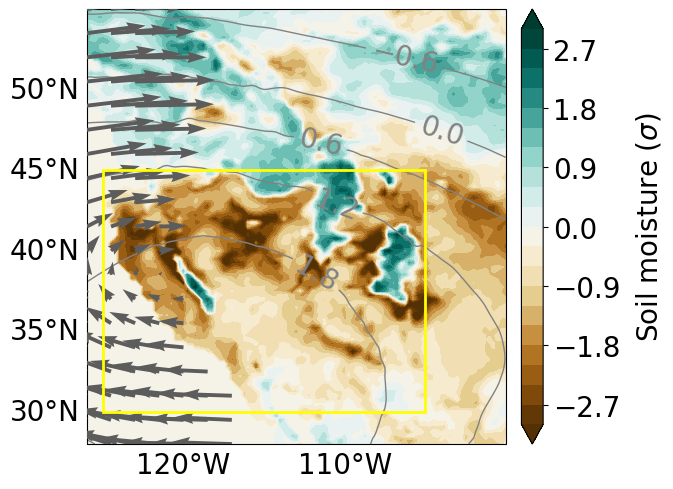

In [5]:
fig, ax = plt.subplots(subplot_kw={'projection': crs}, figsize=(6.5, 5))  

p_swvl1_wave5 = ax.contourf(swvl1_sigma_wave5.lon, swvl1_sigma_wave5.lat, swvl1_sigma_wave5[swvl1], transform=crs, levels=levels, cmap=plt.cm.BrBG, extend='both')
p_z500_wave5 = ax.contour(z500_sigma_wave5.lon, z500_sigma_wave5.lat, z500_sigma_wave5[z], levels=levels[::2], colors='#828282', origin='lower', linestyles='-', linewidths=1)
p_v300_wave5 = ax.quiver(v300_sigma_wave5.lon[::step], v300_sigma_wave5.lat[::step], u300_sigma_wave5[u][::step,::step], v300_sigma_wave5.where(v300_sigma_wave5.v>0)[v][::step,::step], 
                         transform=crs, units='x', scale=0.5, edgecolors='#5c5c5c', color='#5c5c5c', width=0.24, zorder=10) 

cb_wave5 = plt.colorbar(p_swvl1_wave5, pad = pad, ax=ax) 
cb_wave5.set_label("Soil moisture ($\sigma$)", multialignment='center', rotation=90, size=labelsize, labelpad=10) 
cb_wave5.ax.tick_params(labelsize=labelsize)
ax.clabel(p_z500_wave5, inline=True, fontsize=labelsize)

ax.set_extent([lon_bnds[0], lon_bnds[1], lat_bnds[0], lat_bnds[1]], crs)
ax.add_patch(mpatches.Rectangle(xy=[lon_bnds_reg[0], lat_bnds_reg[0]], width=width, height=height, facecolor='none', edgecolor='yellow',
                           linewidth=2, alpha=1.0, transform=crs, zorder=12)) 

gl_wave5 = ax.gridlines(crs, draw_labels=True, color='#ededed', alpha=0.0, linestyle='-') 
gl_wave5.top_labels = False
gl_wave5.right_labels = False
gl_wave5.xformatter = LONGITUDE_FORMATTER
gl_wave5.yformatter = LATITUDE_FORMATTER
gl_wave5.xlabel_style = {'color': 'black', 'size': labelsize}
gl_wave5.ylabel_style = {'color': 'black', 'size': labelsize} 
gl_wave5.xlocator = ticker.FixedLocator([-130, -120, -110, -100])                                                              
gl_wave5.ylocator = ticker.FixedLocator([25, 30, 35, 40, 45, 50, 55])                                                                                    

plt.tight_layout()   

# Save plot
plt.savefig(homepath + 'figures/Fig_1c_1.pdf', format='pdf', dpi=600, bbox_inches='tight') 

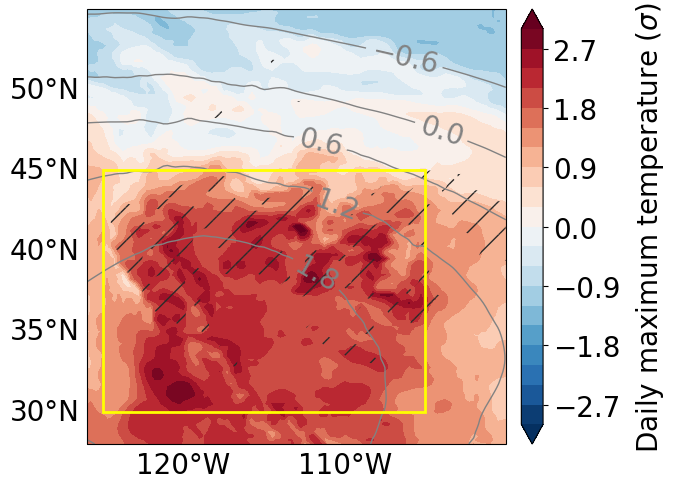

In [6]:
fig, ax = plt.subplots(subplot_kw={'projection': crs}, figsize=(6.5, 5))  

p_t2m_wave5 = ax.contourf(tx_sigma_wave5.lon, tx_sigma_wave5.lat, tx_sigma_wave5[t2m], transform=crs, levels=levels, cmap=plt.cm.RdBu_r, extend='both') 
p_z500_wave5 = ax.contour(z500_sigma_wave5.lon, z500_sigma_wave5.lat, z500_sigma_wave5[z], levels=levels[::2], colors='#828282', origin='lower', linestyles='-', linewidths=1)
p_swvl1_wave5 = ax.contourf(swvl1_sigma_wave5.lon, swvl1_sigma_wave5.lat, swvl1_sigma_wave5[swvl1], transform=crs, 
                      levels=[-5., -4.5, -4.0, -3.5, -3.0, -2.5, -2.0, -1.5], hatches='//', colors='none')

for collection in p_swvl1_wave5.collections:
    collection.set_linewidth(0.)
    collection.set_edgecolor('#2b2b2b')

cb_wave5 = plt.colorbar(p_t2m_wave5, pad = pad, ax=ax) #, shrink = 0.95
cb_wave5.set_label("Daily maximum temperature ($\sigma$)", multialignment='center', rotation=90, size=labelsize, labelpad=10) 
cb_wave5.ax.tick_params(labelsize=labelsize)
ax.clabel(p_z500_wave5, inline=True, fontsize=labelsize)

ax.set_extent([lon_bnds[0], lon_bnds[1], lat_bnds[0], lat_bnds[1]], crs)
ax.add_patch(mpatches.Rectangle(xy=[lon_bnds_reg[0], lat_bnds_reg[0]], width=width, height=height, facecolor='none', edgecolor='yellow',
                           linewidth=2, alpha=1.0, transform=crs, zorder=12)) 

gl_wave5 = ax.gridlines(crs, draw_labels=True, color='#ededed', alpha=0.0, linestyle='-') 
gl_wave5.top_labels = False
gl_wave5.right_labels = False
gl_wave5.xformatter = LONGITUDE_FORMATTER
gl_wave5.yformatter = LATITUDE_FORMATTER
gl_wave5.xlabel_style = {'color': 'black', 'size': labelsize}
gl_wave5.ylabel_style = {'color': 'black', 'size': labelsize} 
gl_wave5.xlocator = ticker.FixedLocator([-130, -120, -110, -100])                                                              
gl_wave5.ylocator = ticker.FixedLocator([25, 30, 35, 40, 45, 50, 55])                                                                                    

plt.tight_layout()   

# Save plot
plt.savefig(homepath + 'figures/Fig_1c_2.pdf', format='pdf', dpi=600, bbox_inches='tight')  

# Fig. 1D: Wave 4

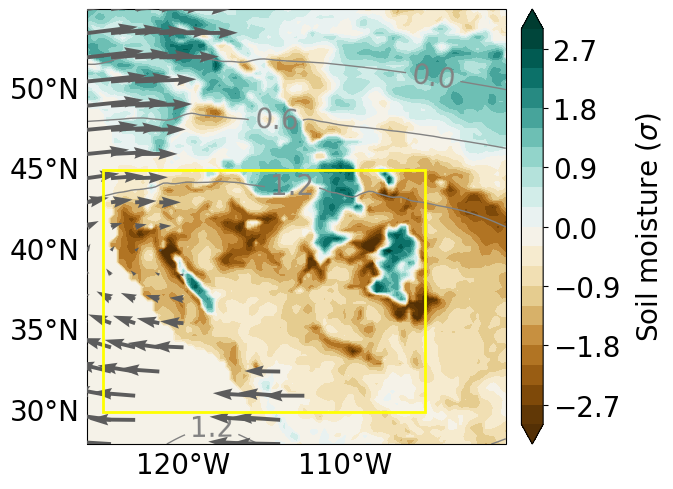

In [7]:
fig, ax = plt.subplots(subplot_kw={'projection': crs}, figsize=(6.5, 5))  

p_swvl1_wave4 = ax.contourf(swvl1_sigma_wave4.lon, swvl1_sigma_wave4.lat, swvl1_sigma_wave4[swvl1], transform=crs, levels=levels, cmap=plt.cm.BrBG, extend='both')
p_z500_wave4 = ax.contour(z500_sigma_wave4.lon, z500_sigma_wave4.lat, z500_sigma_wave4[z], levels=levels[::2], colors='#828282', origin='lower', linestyles='-', linewidths=1)
p_v300_wave4 = ax.quiver(v300_sigma_wave4.lon[::step], v300_sigma_wave4.lat[::step], u300_sigma_wave4[u][::step,::step], v300_sigma_wave4.where(v300_sigma_wave4.v>0)[v][::step,::step], 
                         transform=crs, units='x', scale=0.5, edgecolors='#5c5c5c', color='#5c5c5c', width=0.24, zorder=10) 

cb_wave4 = plt.colorbar(p_swvl1_wave4, pad = pad, ax=ax) 
cb_wave4.set_label("Soil moisture ($\sigma$)", multialignment='center', rotation=90, size=labelsize, labelpad=10) 
cb_wave4.ax.tick_params(labelsize=labelsize)
ax.clabel(p_z500_wave4, inline=True, fontsize=labelsize)

ax.set_extent([lon_bnds[0], lon_bnds[1], lat_bnds[0], lat_bnds[1]], crs)
ax.add_patch(mpatches.Rectangle(xy=[lon_bnds_reg[0], lat_bnds_reg[0]], width=width, height=height, facecolor='none', edgecolor='yellow',
                           linewidth=2, alpha=1.0, transform=crs, zorder=12)) 

gl_wave4 = ax.gridlines(crs, draw_labels=True, color='#ededed', alpha=0.0, linestyle='-') 
gl_wave4.top_labels = False
gl_wave4.right_labels = False
gl_wave4.xformatter = LONGITUDE_FORMATTER
gl_wave4.yformatter = LATITUDE_FORMATTER
gl_wave4.xlabel_style = {'color': 'black', 'size': labelsize}
gl_wave4.ylabel_style = {'color': 'black', 'size': labelsize} 
gl_wave4.xlocator = ticker.FixedLocator([-130, -120, -110, -100])                                                              
gl_wave4.ylocator = ticker.FixedLocator([25, 30, 35, 40, 45, 50, 55])                                                                                    

plt.tight_layout()   

# Save plot
plt.savefig(homepath + 'figures/Fig_1d_1.pdf', format='pdf', dpi=600, bbox_inches='tight') 

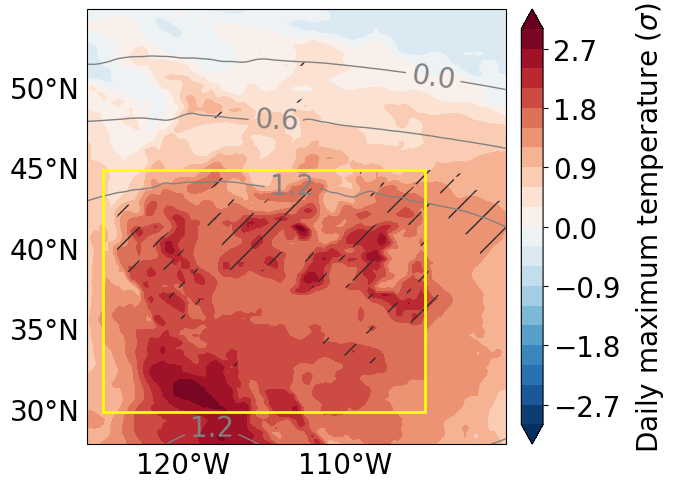

In [ ]:
fig, ax = plt.subplots(subplot_kw={'projection': crs}, figsize=(6.5, 5))  

p_t2m_wave4 = ax.contourf(tx_sigma_wave4.lon, tx_sigma_wave4.lat, tx_sigma_wave4[t2m], transform=crs, levels=levels, cmap=plt.cm.RdBu_r, extend='both') 
p_z500_wave4 = ax.contour(z500_sigma_wave4.lon, z500_sigma_wave4.lat, z500_sigma_wave4[z], levels=levels[::2], colors='#828282', origin='lower', linestyles='-', linewidths=1)
p_swvl1_wave4 = ax.contourf(swvl1_sigma_wave4.lon, swvl1_sigma_wave4.lat, swvl1_sigma_wave4[swvl1], transform=crs, 
                      levels=[-5., -4.5, -4.0, -3.5, -3.0, -2.5, -2.0, -1.5], hatches='//', colors='none')

for collection in p_swvl1_wave4.collections:
    collection.set_linewidth(0.)
    collection.set_edgecolor('#2b2b2b')

cb_wave4 = plt.colorbar(p_t2m_wave4, pad = pad, ax=ax) #, shrink = 0.95
cb_wave4.set_label("Daily maximum temperature ($\sigma$)", multialignment='center', rotation=90, size=labelsize, labelpad=10) 
cb_wave4.ax.tick_params(labelsize=labelsize)
ax.clabel(p_z500_wave4, inline=True, fontsize=labelsize)

ax.set_extent([lon_bnds[0], lon_bnds[1], lat_bnds[0], lat_bnds[1]], crs)
ax.add_patch(mpatches.Rectangle(xy=[lon_bnds_reg[0], lat_bnds_reg[0]], width=width, height=height, facecolor='none', edgecolor='yellow',
                           linewidth=2, alpha=1.0, transform=crs, zorder=12)) 

gl_wave4 = ax.gridlines(crs, draw_labels=True, color='#ededed', alpha=0.0, linestyle='-') 
gl_wave4.top_labels = False
gl_wave4.right_labels = False
gl_wave4.xformatter = LONGITUDE_FORMATTER
gl_wave4.yformatter = LATITUDE_FORMATTER
gl_wave4.xlabel_style = {'color': 'black', 'size': labelsize}
gl_wave4.ylabel_style = {'color': 'black', 'size': labelsize} 
gl_wave4.xlocator = ticker.FixedLocator([-130, -120, -110, -100])                                                              
gl_wave4.ylocator = ticker.FixedLocator([25, 30, 35, 40, 45, 50, 55])                                                                                    

plt.tight_layout()   

# Save plot
plt.savefig(homepath + 'figures/Fig_1d_2.pdf', format='pdf', dpi=600, bbox_inches='tight')  